## Imports


In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

## Setup

In [2]:
sns.set_theme(style = "whitegrid")
plt.rcParams["figure.figsize"] = (10,6)

In [3]:
df = pd.read_csv("Sample_Superstore_Cleaned.csv")

In [4]:
df

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Segment,Country,City,State,Postal Code,Region,Category,Sub-Category,Sales,Quantity,Discount,Profit
0,1,CA-2023-100860,2020-02-29,2020-03-03,Second Class,Consumer,United States,Henderson,Kentucky,42420,South,Furniture,Bookcases,261.9600,2,0.00,41.9136
1,2,CA-2023-105390,2022-06-11,2022-06-15,Second Class,Consumer,United States,Henderson,Kentucky,42420,South,Furniture,Chairs,731.9400,3,0.00,219.5820
2,3,CA-2023-105226,2020-08-12,2020-08-14,Second Class,Corporate,United States,Los Angeles,California,90036,West,Office Supplies,Labels,14.6200,2,0.00,6.8714
3,4,CA-2023-105191,2021-11-30,2021-12-03,Standard Class,Consumer,United States,Fort Lauderdale,Florida,33311,South,Furniture,Tables,957.5775,5,0.45,-383.0310
4,5,CA-2023-103772,2021-08-04,2021-08-10,Standard Class,Consumer,United States,Fort Lauderdale,Florida,33311,South,Office Supplies,Storage,22.3680,2,0.20,2.5164
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9989,9990,CA-2023-103688,2021-09-17,2021-09-22,Second Class,Consumer,United States,Miami,Florida,33180,South,Furniture,Furnishings,25.2480,3,0.20,4.1028
9990,9991,CA-2023-103973,2023-06-29,2023-07-05,Standard Class,Consumer,United States,Costa Mesa,California,92627,West,Furniture,Furnishings,91.9600,2,0.00,15.6332
9991,9992,CA-2023-101185,2022-10-08,2022-10-14,Standard Class,Consumer,United States,Costa Mesa,California,92627,West,Technology,Phones,258.5760,2,0.20,19.3932
9992,9993,CA-2023-103262,2023-10-29,2023-11-01,Standard Class,Consumer,United States,Costa Mesa,California,92627,West,Office Supplies,Paper,29.6000,4,0.00,13.3200


In [5]:
print(f"Dataset.Shape : {df.shape}")
print("\nFirst 3 Rows : ")
print(df.head(3))

Dataset.Shape : (9994, 17)

First 3 Rows : 
   Row ID        Order ID  Order Date   Ship Date     Ship Mode    Segment  \
0       1  CA-2023-100860  2020-02-29  2020-03-03  Second Class   Consumer   
1       2  CA-2023-105390  2022-06-11  2022-06-15  Second Class   Consumer   
2       3  CA-2023-105226  2020-08-12  2020-08-14  Second Class  Corporate   

         Country         City       State  Postal Code Region  \
0  United States    Henderson    Kentucky        42420  South   
1  United States    Henderson    Kentucky        42420  South   
2  United States  Los Angeles  California        90036   West   

          Category Sub-Category   Sales  Quantity  Discount    Profit  
0        Furniture    Bookcases  261.96         2       0.0   41.9136  
1        Furniture       Chairs  731.94         3       0.0  219.5820  
2  Office Supplies       Labels   14.62         2       0.0    6.8714  


## DATA CLEANING & DATETIME FEATURE EXTRACTION

In [6]:
# Check for nulls and duplicated rows
print(f"\nMissing values per Column:\n{df.isnull().sum()[df.isnull().sum() > 0]}")
print(f" Duplicate Rows: {df.duplicated().sum()}")


Missing values per Column:
Series([], dtype: int64)
 Duplicate Rows: 0


In [7]:
# Drop duplicate rows if present
df = df.drop_duplicates()

In [8]:
print(df.columns.tolist())

['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode', 'Segment', 'Country', 'City', 'State', 'Postal Code', 'Region', 'Category', 'Sub-Category', 'Sales', 'Quantity', 'Discount', 'Profit']


In [9]:
# Parse datetime columns
df["Order Date"] = pd.to_datetime(df["Order Date"])
df["Ship Date"] = pd.to_datetime(df["Ship Date"])

In [10]:
df["Order Year"] = df["Order Date"].dt.year
df["Order Month"] = df["Order Date"].dt.month_name()
df["Order YearMonth"] = df["Order Date"].dt.to_period("M")

In [11]:
df["Shipping Days"] = (df["Ship Date"] - df["Order Date"]).dt.days

 ## PROFIT MARGIN & CONDITIONAL METRIC ENGINEERING (NumPy)

In [12]:
# Calculate Profit Margin per order: Profit / Sales (safely handling zero sales)
df["Profit_Margin"] = np.where(df["Sales"] > 0 , df["Profit"]/df["Sales"], 0.0)

In [13]:
df["Is_Loss_Making"] = np.where(df["Profit"] < 0, 1, 0)

In [14]:
df["Profitability_Status"] = np.where(df["Profit"] > 0 , "Profitable", np.where(df["Profit"] < 0, "Loss", "Breakeven"))

In [15]:
print("\nProfitability Breakdown : ")
print(df["Profitability_Status"].value_counts(normalize = True).round(3) * 100)


Profitability Breakdown : 
Profitability_Status
Profitable    80.6
Loss          18.7
Breakeven      0.7
Name: proportion, dtype: float64


## BUSINESS QUESTION 1: SUB-CATEGORY SALES VS. PROFITABILITY

In [16]:
# Aggregate by Category and Sub-Category
subcat_summary = (
  df.groupby(["Category","Sub-Category"]) [["Sales","Profit","Discount"]]
    .agg({"Sales": "sum", "Profit": "sum", "Discount": "mean"})
      )

In [17]:
# Recalculate overall aggregate Profit Margin
subcat_summary["Profit_Margin"] = (
    subcat_summary["Profit"]/ subcat_summary["Sales"]
)

In [18]:
# Sort by lowest profit to identify bottom performers
subcat_summary = subcat_summary.sort_values(by="Profit", ascending=True)

In [19]:
print("n\--- Bottom 5 Most Unprofitable Sub-Categories ---")
print(
    subcat_summary.head(5).to_string(
        index=False,
        formatters={
            "Sales": "${:,.2f}".format,
            "Profit": "${:,.2f}".format,
            "Discount": "{:.1%}".format,
            "Profit_Margin": "{:.1%}".format,
        },
    )  
            
)

n\--- Bottom 5 Most Unprofitable Sub-Categories ---
      Sales      Profit Discount Profit_Margin
$206,965.53 $-17,725.48    26.1%         -8.6%
$114,880.00  $-3,472.56    21.1%         -3.0%
 $46,673.54  $-1,189.10     7.7%         -2.5%
  $3,024.28     $949.52     8.2%         31.4%
$189,238.63   $3,384.76    30.6%          1.8%


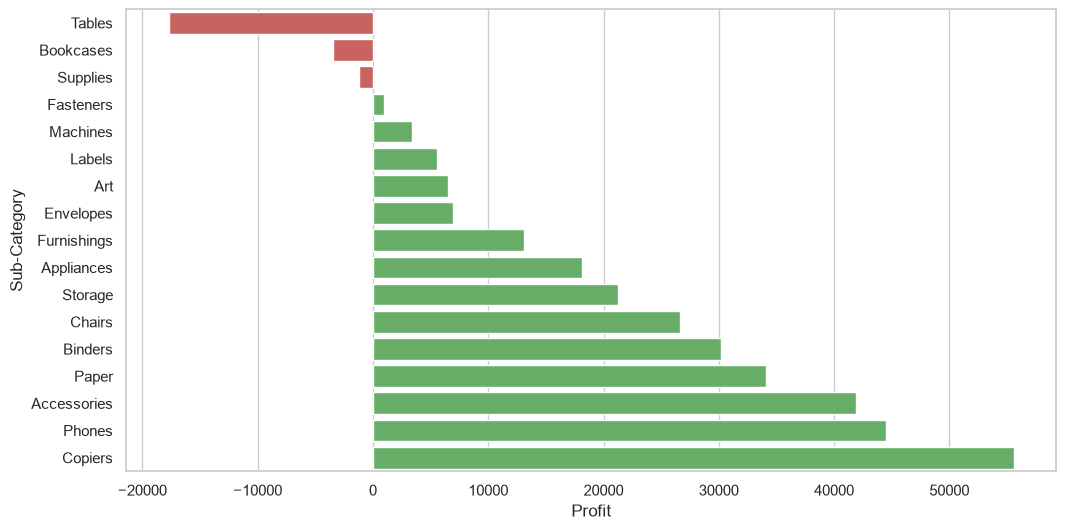

In [34]:
# Plot: Sub-Category Profitability Diagnostic
import os

figures_dir = r"D:\Superstore Retail Sales & Profit Margin Diagnostics\superstore-margin-diagnostic\reports\figures"
os.makedirs(figures_dir, exist_ok=True)
plt.figure(figsize=(12, 6))
colors = [
    "#d9534f" if p < 0 else "#5cb85c"
    for p in subcat_summary.sort_values(by="Profit")["Profit"]
]
sns.barplot(
    data = subcat_summary.sort_values(by="Profit"),
    x="Profit",
    y="Sub-Category",
    palette=colors,
    hue="Sub-Category",
    legend=False,
)
plt.savefig(os.path.join(figures_dir, "subcategory_profit_margin.png"), dpi=300, bbox_inches="tight")

## BUSINESS QUESTION 2: SHIPPING MODE PERFORMANCE & COSTS

In [21]:
# Analyze shipping mode dynamics
Shipping_summary = (
    df.groupby ("Ship Mode")
    .agg(
        Order_Counts = ("Order ID","nunique"),
        Total_Sales = ("Sales","sum"),
        Total_Profit = ("Profit", "sum"),
        Avg_Shipping_Days = ("Shipping Days","mean"),
        Loss_Orders = ("Is_Loss_Making","sum"),
    )
    .reset_index()
)  

In [22]:
Shipping_summary["Profit_Margin"] = (
    Shipping_summary["Total_Profit"] / Shipping_summary["Total_Sales"]
)
Shipping_summary["Loss_Order_Rate"] = (
    Shipping_summary["Loss_Orders"] / Shipping_summary["Order_Counts"]
)

In [23]:
print("n\ --- Shipping Mode diagnostic --- ")
print (
    Shipping_summary.to_string(
        index= False,
        formatters= {
            "Total_Profit" :lambda x: f"${x:,.2f}",
             "Total_Sales" : lambda x: f"${x:,.2f}",
             "Profit_Margin" :lambda x: f"{x:.1%}",
             "Loss_Order_Rate":lambda x: f"{x:.1%}",
              "Avg_Shipping_Days":lambda x: f"{x:.1f}days",
        }
     )
 )   
                  

n\ --- Shipping Mode diagnostic --- 
     Ship Mode  Order_Counts   Total_Sales Total_Profit Avg_Shipping_Days  Loss_Orders Profit_Margin Loss_Order_Rate
   First Class          1359   $351,428.42   $48,969.84           2.0days          293         13.9%           21.6%
      Same Day           520   $128,363.12   $15,891.76           0.5days           98         12.4%           18.8%
  Second Class          1658   $459,193.57   $57,446.64           3.5days          307         12.5%           18.5%
Standard Class          3736 $1,358,215.74  $164,088.79           5.0days         1173         12.1%           31.4%


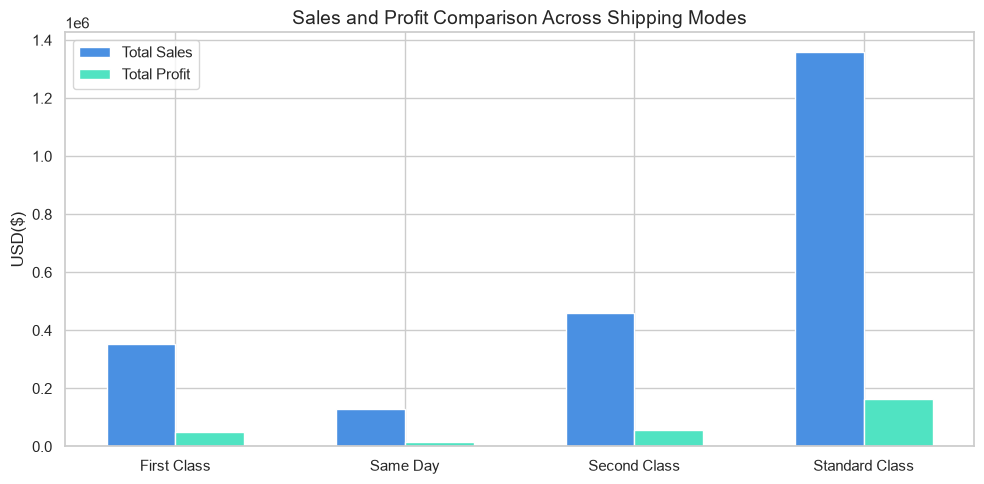

In [24]:
# Plot: Profit vs Sales by Shipping Mode
# 1. create the figure and axes
fig, ax1 = plt.subplots(figsize=(10,5))
x = np.arange(len(Shipping_summary["Ship Mode"]))
width = 0.3

# 2. plot the data
ax1.bar(
    x - width / 2,
    Shipping_summary["Total_Sales"],
    width,
    label = "Total Sales",
    color="#4a90e2",
)
ax1.bar(
    x + width / 2,
    Shipping_summary["Total_Profit"],
    width,
    label = "Total Profit",
    color="#50e3c2",
)

# 3. format and dispay
ax1.set_xticks(x)
ax1.set_xticklabels(Shipping_summary["Ship Mode"])
ax1.set_ylabel("USD($)")
ax1.set_title("Sales and Profit Comparison Across Shipping Modes", fontsize = 14)
ax1.legend()
plt.tight_layout()
plt.show()

 ## ROOT CAUSE DRILL-DOWN: DISCOUNT VS PROFIT DRIVERS

In [25]:
# High discounts frequently erode margins; analyze discount bins
df["Discount_Tier"] = pd.cut(
    df["Discount"],
    bins=[-0.01, 0.0, 0.2, 0.5, 1.0],
    labels=["0% (None)", "1-20% (Low)", "21-50% (Moderate)", ">50% (Heavy)"],
)

In [26]:
discount_impact = (
    df.groupby("Discount_Tier")
    .agg(
        Order_Count=("Row ID", "count"),
        Total_Sales=("Sales", "sum"),
        Total_Profit=("Profit", "sum"),
    )
    .reset_index()
)
        

In [27]:
discount_impact["Profit_Margin"] = (
    discount_impact["Total_Profit"] / discount_impact["Total_Sales"]
)

In [28]:
print("\n--- Impact of Discount Tiers on Net Profit ---")
print(
    discount_impact.to_string(
        index=False,
        formatters={
            "Total_Sales": "${:,.2f}".format,
            "Total_Profit": "${:,.2f}".format,
            "Profit_Margin": "{:.1%}".format,
        },
    )
)


--- Impact of Discount Tiers on Net Profit ---
    Discount_Tier  Order_Count   Total_Sales Total_Profit Profit_Margin
        0% (None)         4798 $1,087,908.47  $320,987.60         29.5%
      1-20% (Low)         3803   $846,522.24  $100,785.47         11.9%
21-50% (Moderate)          537   $298,541.41  $-58,817.00        -19.7%
     >50% (Heavy)          856    $64,228.74  $-76,559.05       -119.2%


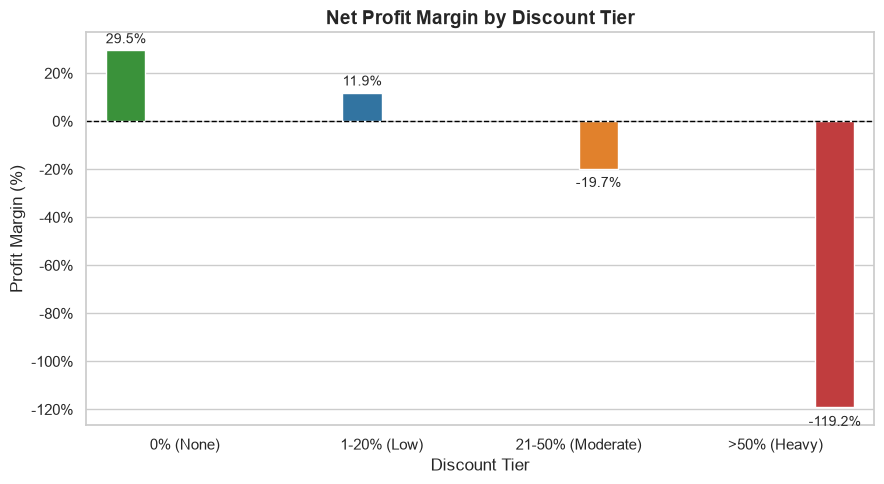

In [36]:
## Discount Tier v/s Profit Margin Visualization
plt.figure(figsize=(9, 5))
colors = ["#2ca02c", "#1f77b4", "#ff7f0e", "#d62728"]

ax = sns.barplot(
    data=discount_impact,
    x="Discount_Tier",
    y="Profit_Margin",
    palette=colors,
    hue="Discount_Tier",
    legend=False,
)

plt.axhline(0, color="black", linestyle="--", linewidth=1)
plt.title("Net Profit Margin by Discount Tier", fontsize=14, weight="bold")
plt.ylabel("Profit Margin (%)")
plt.xlabel("Discount Tier")

# Format y-axis as percentage
ax.yaxis.set_major_formatter(
    plt.matplotlib.ticker.FuncFormatter(lambda y, _: f"{y*100:.0f}%")
)

# Add data labels on top/bottom of each bar
for p in ax.patches:
    height = p.get_height()
    va = "bottom" if height >= 0 else "top"
    ax.annotate(
        f"{height*100:.1f}%",
        (p.get_x() + p.get_width() / 2.0, height),
        ha="center",
        va=va,
        fontsize=10,
        xytext=(0, 3 if height >= 0 else -6),
        textcoords="offset points",
    )

plt.tight_layout()
plt.savefig(os.path.join(figures_dir, "discount_tier_margin.png"), dpi=300, bbox_inches="tight")
plt.show()

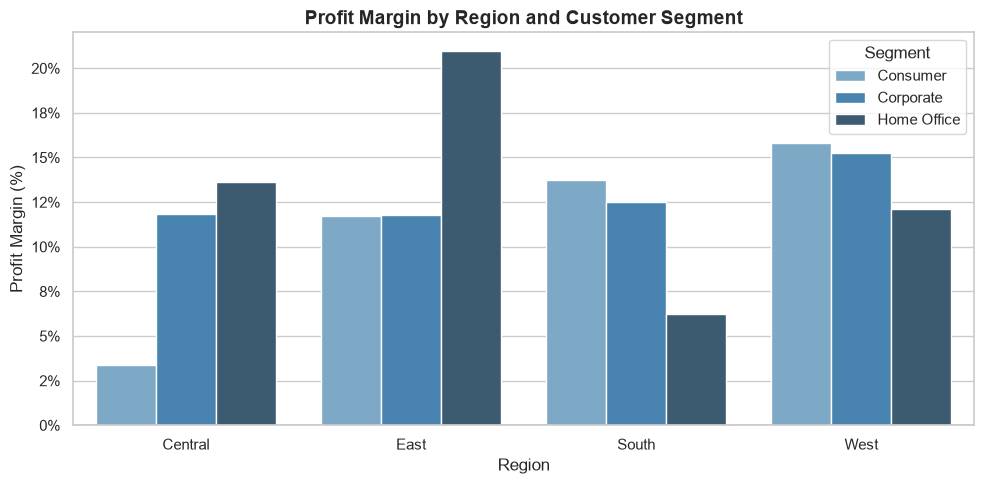

In [30]:
# Group by Region and Segment
regional_summary = (
    df.groupby(["Region", "Segment"])
    .agg(
        Total_Sales=("Sales", "sum"),
        Total_Profit=("Profit", "sum"),
        Avg_Discount=("Discount", "mean"),
    )
    .reset_index()
)

regional_summary["Profit_Margin"] = (
    regional_summary["Total_Profit"] / regional_summary["Total_Sales"]
)

# Plot Regional breakdown
plt.figure(figsize=(10, 5))
ax = sns.barplot(
    data=regional_summary,
    x="Region",
    y="Profit_Margin",
    hue="Segment",
    palette="Blues_d",
)

plt.axhline(0, color="black", linestyle="--", linewidth=1)
plt.title(
    "Profit Margin by Region and Customer Segment", fontsize=14, weight="bold"
)
plt.ylabel("Profit Margin (%)")
plt.xlabel("Region")

ax.yaxis.set_major_formatter(
    plt.matplotlib.ticker.FuncFormatter(lambda y, _: f"{y*100:.0f}%")
)
plt.legend(title="Segment", frameon=True)
plt.tight_layout()
plt.show()

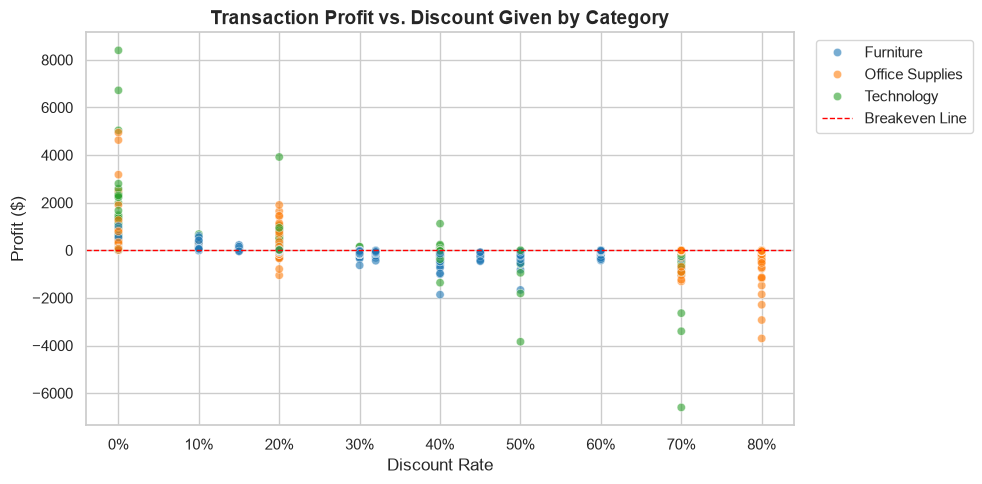

In [41]:
## Discount vs. Profit Correlation Scatter Plot
plt.figure(figsize=(10, 5))
sns.scatterplot(
    data=df,
    x="Discount",
    y="Profit",
    hue="Category",
    alpha=0.6,
    palette="tab10",
)

plt.axhline(0, color="red", linestyle="--", linewidth=1, label="Breakeven Line")
plt.title(
    "Transaction Profit vs. Discount Given by Category",
    fontsize=14,
    weight="bold",
)
plt.xlabel("Discount Rate")
plt.ylabel("Profit ($)")
plt.gca().xaxis.set_major_formatter(
    plt.matplotlib.ticker.FuncFormatter(lambda x, _: f"{x*100:.0f}%")
)
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.savefig(os.path.join(figures_dir, "discount_vs_profit_scatter.png"), dpi=300, bbox_inches="tight")
plt.show()

## Executive Summary & Strategic Recommendations

### Key Findings
1. **The 20% Discount Cliff:** 
   - Orders with 0% to 20% discount generate steady positive margins (11.9% to 29.5%).
   - Any discount above 20% destroys margin, plunging into deep losses (-19.7% for moderate discounts and -119.2% for heavy discounts >50%).
2. **Product Sub-Category Losses:**
   - **Tables** and **Bookcases** are the biggest net loss drivers, largely due to high shipping footprints and high promotional discount rates (>20%).
3. **Shipping Mode Inefficiency:**
   - **Standard Class** handles the largest sales volume but also accounts for **31.4% loss-making orders**, showing that slow delivery is not offsetting thin margins.

---

### Actionable Business Recommendations
* **Enforce Discount Caps:** Cap representative discounts at a strict 20% maximum. Implement manager-approval workflows for any requested override.
* **Review Furniture Pricing & Shipping:** Eliminate heavy promotional discounting on high-bulk items (Tables and Bookcases) or introduce a freight surcharge.
* **Set Minimum Order Values for Free Shipping:** Standard Class orders should require a minimum order threshold to avoid loss-making small orders.